# Task 1 · ACT versus Diffusion

Matched SO-101 cube-placement trials from SO101_Task1_25_Episode_Evaluation.xlsx. The 25 rows below reproduce the two worksheets in episode order. A 1 denotes completion of all four stages. The observations are embedded so the notebook can run independently of the workbook.

Dependencies: Python, matplotlib, NumPy, SciPy and [TRI-ML STEP at the evaluated commit](https://github.com/TRI-ML/sequentialized_barnard_tests/tree/3ae1623906f82fe472a352ed4a6b8e4a712f1f3d). In a fresh notebook environment run `%pip install git+https://github.com/TRI-ML/sequentialized_barnard_tests.git@3ae1623906f82fe472a352ed4a6b8e4a712f1f3d` first.

In [1]:
import csv
from io import StringIO, BytesIO
from IPython.display import Image, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta, binomtest
from sequentialized_barnard_tests import Decision, Hypothesis, MirroredStepTest

## Matched rollout outcomes

In [2]:
data = """order,layout_id,ACT,Diffusion
1,C01,0,1
2,C02,0,1
3,C03,1,0
4,C04,1,0
5,C05,1,0
6,C06,1,0
7,C07,1,0
8,C08,0,1
9,C09,1,1
10,C10,1,1
11,C11,0,1
12,C12,0,1
13,C13,1,1
14,C14,1,1
15,C15,1,0
16,C16,1,1
17,C17,1,1
18,C18,0,1
19,C19,1,1
20,C20,1,1
21,C21,1,0
22,C22,0,0
23,C23,1,0
24,C24,0,0
25,C25,1,0"""
records = list(csv.DictReader(StringIO(data)))
assert [int(r["order"]) for r in records] == list(range(1,26))
assert len({r["layout_id"] for r in records}) == 25
trials = [(int(r["ACT"]), int(r["Diffusion"])) for r in records]
assert all(value in (0, 1) for pair in trials for value in pair)
print(data)

order,layout_id,ACT,Diffusion
1,C01,0,1
2,C02,0,1
3,C03,1,0
4,C04,1,0
5,C05,1,0
6,C06,1,0
7,C07,1,0
8,C08,0,1
9,C09,1,1
10,C10,1,1
11,C11,0,1
12,C12,0,1
13,C13,1,1
14,C14,1,1
15,C15,1,0
16,C16,1,1
17,C17,1,1
18,C18,0,1
19,C19,1,1
20,C20,1,1
21,C21,1,0
22,C22,0,0
23,C23,1,0
24,C24,0,0
25,C25,1,0


## Official quick-start STEP comparison

Adapted from the [TRI-ML quick-start notebook](https://github.com/TRI-ML/sequentialized_barnard_tests/blob/main/quick_start.ipynb). Columns 0 and 1 are ACT and Diffusion in workbook episode order. The assignment specifies a budget of 25, alpha 0.10 and mirrored ranking.

In [3]:
example_data = np.asarray(trials, dtype=int)
shape_parameter = 0.0
use_p_norm = False
budget = n_max = 25
alpha = 0.10
alternative_hypothesis = Hypothesis.P0LessThanP1
step_policy = MirroredStepTest(alternative_hypothesis, n_max, alpha, shape_parameter, use_p_norm,
                               inference_mode="ranking", random_seed=42)
step_result = step_policy.run_on_sequence(example_data[:, 0], example_data[:, 1])
print("Decision:", step_result.decision)
print("Time:", step_result.info["Time"])
winner = {Decision.AcceptAlternative: "Diffusion", Decision.AcceptNull: "ACT",
          Decision.FailToDecide: None}[step_result.decision]
decision_line = (f"Inconclusive after {n_max} trials per policy." if winner is None else
                 f"{winner} favored at trial {step_result.info['Time']}.")
print(decision_line)

Decision: Decision.FailToDecide
Time: 25
Inconclusive after 25 trials per policy.


## Full-budget estimates and posterior violins

Each violin shows a Beta(s + 1, n − s + 1) posterior under a uniform prior. A shared letter means STEP did not separate the two policies.

Inconclusive after 25 trials per policy.
n_max=25, alpha_pair=0.10, linear risk budget, ranking, seed=42
Official STEP commit 3ae1623906f82fe472a352ed4a6b8e4a712f1f3d
ACT: 17 successes, 8 failures, 68.0% (90% Wilson CI 51.6% to 80.9%)
Diffusion: 14 successes, 11 failures, 56.0% (90% Wilson CI 39.9% to 70.9%)


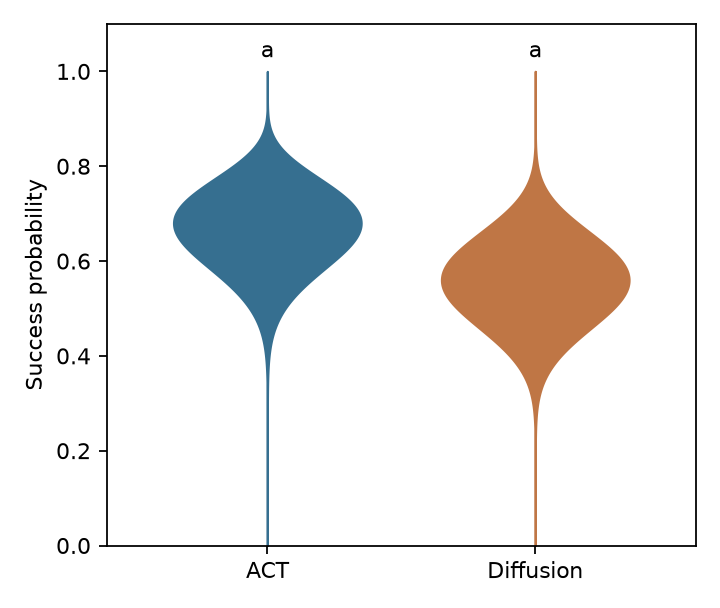

In [4]:
lines = [decision_line, f"n_max={budget}, alpha_pair=0.10, linear risk budget, ranking, seed=42",
         "Official STEP commit 3ae1623906f82fe472a352ed4a6b8e4a712f1f3d"]
fig, ax = plt.subplots(figsize=(4.5, 3.8))
probability = np.linspace(0, 1, 501)
for index, (name, outcomes) in enumerate(zip(("ACT", "Diffusion"), zip(*trials))):
    successes, n = sum(outcomes), len(outcomes)
    interval = binomtest(successes, n).proportion_ci(confidence_level=0.90, method="wilson")
    lines.append(f"{name}: {successes} successes, {n-successes} failures, "
                 f"{successes/n:.1%} (90% Wilson CI {interval.low:.1%} to {interval.high:.1%})")
    density = beta.pdf(probability, successes + 1, n - successes + 1)
    width = 0.35 * density / density.max()
    ax.fill_betweenx(probability, index-width, index+width, color=["#366f90", "#bf7645"][index])
    ax.text(index, 1.03, "a" if winner in (None, name) else "b", ha="center")
ax.set(xticks=[0, 1], xticklabels=["ACT", "Diffusion"], xlim=(-0.6, 1.6),
       ylim=(0, 1.1), yticks=np.linspace(0, 1, 6), ylabel="Success probability")
fig.tight_layout()

print("\n".join(lines))
image = BytesIO()
fig.savefig(image, format="png", dpi=160)
plt.close(fig)
display(Image(data=image.getvalue()))